In [1]:
from sklearn.gaussian_process import GaussianProcessRegressor, kernels
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from pathlib import Path

from multiprocessing import Pool
import sys
from astropy.io import fits

In [271]:
name_fields = ['XMM', 'VVDS', 'GAMA09H', 'GAMA15H', 'WIDE12H', 'HECTOMAP']
number_patches = [8, 25, 23, 7, 26, 13]
_GALAXY_COUNTS_TOMOBIN_ = {}

for field, Npatch in zip(name_fields, number_patches):
    dats = [
        fits.getdata(f'~/HSCNG/data/real/hscy3_shape_chopped_{field}_{i}.fits')
        for i in range(Npatch)
    ]
    dat = np.concatenate(dats)
    _numbers = []
    for tomo_bin in [1, 2, 3, 4]:
        _numbers.append((dat['hsc_y3_zbin'] == tomo_bin).sum())
    _GALAXY_COUNTS_TOMOBIN_[field] = _numbers

# SBI
## data C_ell
50 cosmologies * 50 realizations

2500 datas, each cosmology lets split ~20% as validation, which is 50 * 40 training + 50 * 10 testing

in the SBI paper, they first use optuna to optimize the hyperparameters, and then use 

In [151]:
cosmo_pars = np.loadtxt('/home/hedi/HSCNG/data/cosmo_params.txt', skiprows=1)
Om = cosmo_pars[:,1]
S8 = cosmo_pars[:,3]

In [152]:
Cl_tomo = []

for tomo in [1, 2, 3, 4]:
    Cl_cosmo_varied = []
    for cosmology_id in range(50):
        Cls = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/power_spectrum/model{cosmology_id}_Clee_z{tomo}_{field}.npy')     # 50 realizations here
            Cls.append(dat)
        Cls = np.array(Cls)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        Cl_cosmo_varied.append(np.average(Cls, axis=0, weights=weights))

    Cl_tomo.append(np.array(Cl_cosmo_varied))
Cl_tomo = np.array(Cl_tomo)

In [153]:
def pre_process_C_ell(Cl_tomo, ell_min=100, ell_max=2000):
    """
    Preprocess the C_ell data by selecting a range of ell values and flattening the data.
    
    Parameters:
    Cl_tomo (numpy.ndarray): The input C_ell data with shape (tomobin, cosmology_id, realization, ell).
    ell_min (int): The minimum ell value to consider.
    ell_max (int): The maximum ell value to consider.
    
    Returns:
    numpy.ndarray: The preprocessed and flattened C_ell data.
    """
    import pymaster as nmt
    l_edges_log = np.unique(np.logspace(np.log10(80), np.log10(6500),15))
    binner = nmt.NmtBinFlat(l_edges_log[:-1], l_edges_log[1:]) #Namaster power spectrum binner 
    xx = binner.get_effective_ells()

    slice_ell = (xx >= ell_min) & (xx <= ell_max)          # apply a cut here.
    
    # Flatten the data across tomobin, cosmology_id, and realization dimensions
    Cl_concat = np.concat(Cl_tomo[:3, :, :, slice_ell], axis=2)
        # lets discard tomo bin 4 first, which is said to have "outliers"
    return Cl_concat

In [154]:
C_ell_concat = pre_process_C_ell(Cl_tomo, ell_min=300, ell_max=2000)

## data peaks & minima

In [155]:
peak_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/peaks/model{cosmology_id}_Peaks_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        signal_cosmo_varied.append(np.sum(signals, axis=0))

    peak_tomo.append(np.array(signal_cosmo_varied))
peak_tomo = np.array(peak_tomo)

min_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/minima/model{cosmology_id}_Minima_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)     # field, realization, kappa
        signal_cosmo_varied.append(np.sum(signals, axis=0))

    min_tomo.append(np.array(signal_cosmo_varied))
min_tomo = np.array(min_tomo)

In [156]:
def pre_process_peaks(peak_tomo, threshold=15):
    """
    Preprocess the peak data by applying a threshold and flattening the data across tomobin, cosmology_id, and realization dimensions.
    
    Parameters:
    - peak_tomo: numpy array of shape (tomobin, cosmology_id, realization, peak_value)
    - threshold: float, the threshold value to filter peaks
    
    Returns:
    - peak_concat: numpy array of shape (tomobin * cosmology_id * realization, filtered_peak_values)
    """
    # Apply threshold
    select_indice = (peak_tomo > threshold).any(axis=(0, 1, 2))
    
    # Flatten the data across tomobin, cosmology_id, and realization dimensions
    peak_concat = np.concatenate(peak_tomo[:, :, :, select_indice], axis=2)
    
    return peak_concat

In [157]:
peak_concat = pre_process_peaks(peak_tomo, threshold=15)
min_concat = pre_process_peaks(min_tomo, threshold=15)

## data PDF

In [158]:
pdf_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/pdf/model{cosmology_id}_pdf_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    pdf_tomo.append(np.array(signal_cosmo_varied))
pdf_tomo = np.array(pdf_tomo)

In [164]:
pdf_concat = np.concatenate(pdf_tomo[:, :, :, 3:], axis=2)      # cut the first 3 bins according to Thiele et al. 23

# data MFs

In [165]:
V0_tomo = []
V1_tomo = []
V2_tomo = []

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V0_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V0_tomo.append(np.array(signal_cosmo_varied))
V0_tomo = np.array(V0_tomo)

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V1_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V1_tomo.append(np.array(signal_cosmo_varied))
V1_tomo = np.array(V1_tomo)

for tomo in [1, 2, 3, 4]:
    signal_cosmo_varied = []
    for cosmology_id in range(50):
        signals = []
        for field in name_fields:
            dat = np.load(f'/lustre/work/gmarques/HSC_Y3_analysis_Gabriela/stats_cosmo_varied/MFs/model{cosmology_id}_V2_z{tomo}_{field}.npy')     # 50 realizations here
            signals.append(dat)
        signals = np.array(signals)
        weights = [
            _GALAXY_COUNTS_TOMOBIN_[field][tomo - 1] for field in name_fields
        ]
        signal_cosmo_varied.append(np.average(signals, axis=0, weights=weights))

    V2_tomo.append(np.array(signal_cosmo_varied))
V2_tomo = np.array(V2_tomo)

In [169]:
V0_concat = np.concatenate(V0_tomo, axis=2)
V1_concat = np.concatenate(V1_tomo, axis=2)
V2_concat = np.concatenate(V2_tomo, axis=2)

# concat data together

In [170]:
def train_test_split(
    data,
    label,
    test_size=0.2,
    leaveoutindex=None,
    random_state=42,
):

    rng = np.random.default_rng(random_state)

    n_cosmo, n_real, _ = data.shape
    n_train = int(n_real * (1 - test_size))

    label = np.asarray(label)

    X_train = []
    X_test = []

    theta_train = []
    theta_test = []

    for cosmo_id in range(n_cosmo):

        if leaveoutindex is not None and cosmo_id == leaveoutindex:
            continue

        # ONE realization split for this cosmology
        indices = rng.permutation(n_real)

        idx_train = indices[:n_train]
        idx_test = indices[n_train:]

        X_train.append(data[cosmo_id, idx_train, :])
        X_test.append(data[cosmo_id, idx_test, :])

        theta_c = np.atleast_1d(label[cosmo_id])

        theta_train.append(
            np.repeat(
                theta_c[None, :],
                len(idx_train),
                axis=0,
            )
        )

        theta_test.append(
            np.repeat(
                theta_c[None, :],
                len(idx_test),
                axis=0,
            )
        )

    return (
        np.concatenate(X_train),
        np.concatenate(X_test),
        np.concatenate(theta_train),
        np.concatenate(theta_test),
    )

In [171]:
signals_concat = np.concatenate([
    C_ell_concat, 
    peak_concat, 
    min_concat,
    pdf_concat,
    V0_concat,
    V1_concat,
    V2_concat
    ], axis=2)

print(signals_concat.shape)

(50, 50, 394)


In [172]:
dat_train, dat_test, label_train, label_test = train_test_split(signals_concat, label=np.c_[S8, Om], test_size=0.2, leaveoutindex=None, random_state=42)

In [173]:
print("data_train shape:", dat_train.shape)
print("data_test shape:", dat_test.shape)

data_train shape: (2000, 394)
data_test shape: (500, 394)


In [174]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

# ------------------------------------------------------------
# Standardize C_ell using TRAINING SET ONLY
# ------------------------------------------------------------
x_mean = dat_train.mean(axis=0)
x_std = dat_train.std(axis=0)

# protect against zero-variance bins
x_std[x_std == 0] = 1.0

x_train_np = (dat_train - x_mean) / x_std
x_test_np = (dat_test - x_mean) / x_std

x_train = torch.tensor(x_train_np, dtype=torch.float32)
x_test = torch.tensor(x_test_np, dtype=torch.float32)

# SBI theta must have shape (N, n_parameters)
theta_train = torch.tensor(
    label_train,
    dtype=torch.float32
)

theta_test = torch.tensor(
    label_test,
    dtype=torch.float32
)

print("x_train:", x_train.shape)
print("theta_train:", theta_train.shape)
print("x_test:", x_test.shape)
print("theta_test:", theta_test.shape)

device: cpu
x_train: torch.Size([2000, 394])
theta_train: torch.Size([2000, 2])
x_test: torch.Size([500, 394])
theta_test: torch.Size([500, 2])


In [176]:
class ClEmbedding(nn.Module):
    def __init__(self, n_input, n_latent=8):
        super().__init__()

        self.net = nn.Sequential(            
            nn.Linear(n_input, 64),
            nn.GELU(),

            nn.Linear(64, 32),
            nn.GELU(),

            nn.Linear(32, n_latent),
        )

    def forward(self, x):
        return self.net(x)


embedding_net = ClEmbedding(
    n_input=x_train.shape[1],
    n_latent=16,
)

print(embedding_net)

ClEmbedding(
  (net): Sequential(
    (0): Linear(in_features=394, out_features=64, bias=True)
    (1): GELU(approximate='none')
    (2): Linear(in_features=64, out_features=32, bias=True)
    (3): GELU(approximate='none')
    (4): Linear(in_features=32, out_features=16, bias=True)
  )
)


In [177]:
from sbi.inference import SNPE
from sbi.utils import BoxUniform

# posterior_nn location differs slightly between sbi versions
try:
    from sbi.neural_nets import posterior_nn
except ImportError:
    from sbi.utils.get_nn_models import posterior_nn

/var/tmp/pbs.599587.idark/ipykernel_273914/1760096567.py:1: FutureWarning: `sbi.inference.SNPE` is deprecated since sbi v0.27.0 and will be removed in v0.28.0. Use `sbi.inference.NPE_C` instead.
  from sbi.inference import SNPE


In [178]:
prior = BoxUniform(
    low=torch.tensor([S8.min()-0.01, Om.min()-0.01], dtype=torch.float32),
    high=torch.tensor([S8.max()+0.01, Om.max()+0.01], dtype=torch.float32),
)

In [ ]:
density_estimator = posterior_nn(       # so according to Leander, we need some kind of different learning rate for embedding part and the rest.
    model="mdn",
    hidden_features=32,
    num_components=5,
    embedding_net=embedding_net,
    z_score_x="none"
)

In [180]:
inference = SNPE(
    prior=prior,
    density_estimator=density_estimator,
    device=device,
)

inference = inference.append_simulations(
    theta_train,
    x_train,
)

trained_density_estimator = inference.train(
    training_batch_size=128,
    learning_rate=1e-4,

    # sbi takes a fraction of x_train as its internal validation set
    validation_fraction=0.2,

    stop_after_epochs=15,
    max_num_epochs=500,

    show_train_summary=True,
)

summary = inference.summary

/home/hedi/data/miniforge3/envs/sbi/lib/python3.11/site-packages/sbi/inference/trainers/npe/npe_base.py:211: UserWarning: Data has extreme outliers in dimension(s) [102, 117, 166, 168, 169, 170, 181, 182, 183, 184, 185, 186, 187, 203, 223, 224, 243, 244, 251, 260, 261, 319, 320, 336, 337] (beyond 10.0x IQR from quartiles). This may cause precision loss during z-scoring, where distinct values become indistinguishable. Consider removing outliers from your data or setting `z_score_x='none'` (though this may affect training).
  warn_if_invalid_for_zscoring(x)


 Neural network successfully converged after 146 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 146
        Best validation performance: -3.1537
        -------------------------
        


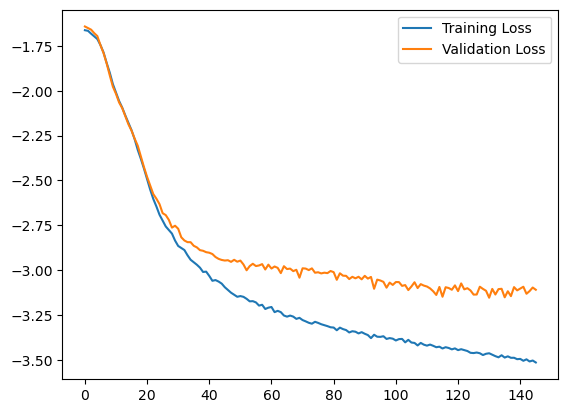

In [181]:
plt.plot(summary['training_loss'], label='Training Loss')
plt.plot(summary['validation_loss'], label='Validation Loss')
plt.legend()

In [182]:
posterior = inference.build_posterior(
    trained_density_estimator
)

truth = [0.73513 0.10721]
raw median = [0.78840667 0.08328144]
raw 16/84 = [[0.74807061 0.05280494]
 [0.83058989 0.11546884]]
raw min = [ 0.6494887  -0.15834165]
raw max = [1.0027919  0.24391042]


/var/tmp/pbs.599587.idark/ipykernel_273914/18891687.py:4: UserWarning: 67.1% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samples_raw = posterior.sample(


Text(0, 0.5, '$\\Omega_m$')

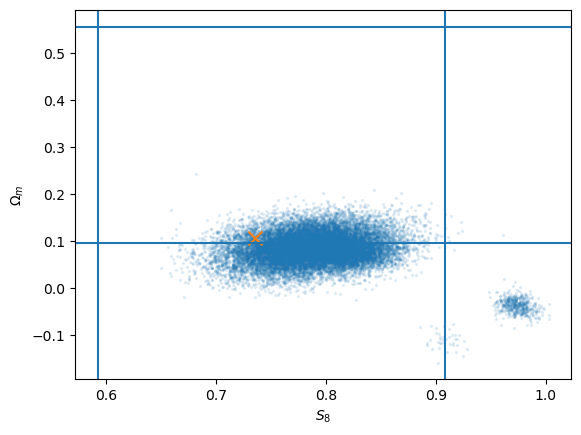

In [183]:
i = 30   # for example, one of your suspicious cases
x_obs = x_test[i]

samples_raw = posterior.sample(
    (20000,),
    x=x_obs,
    reject_outside_prior=False,
    show_progress_bars=False,
).cpu().detach().numpy()

print("truth =", theta_test[i].numpy())

print("raw median =", np.median(samples_raw, axis=0))
print("raw 16/84 =", np.percentile(samples_raw, [16, 84], axis=0))

print("raw min =", samples_raw.min(axis=0))
print("raw max =", samples_raw.max(axis=0))

plt.scatter(
    samples_raw[:, 0],
    samples_raw[:, 1],
    s=2,
    alpha=0.1,
)

plt.axvline(S8.min()-0.01)
plt.axvline(S8.max()+0.01)

plt.axhline(Om.min()-0.01)
plt.axhline(Om.max()+0.01)

plt.scatter(
    theta_test[i, 0],
    theta_test[i, 1],
    marker="x",
    s=100,
)

plt.xlabel(r"$S_8$")
plt.ylabel(r"$\Omega_m$")

In [184]:
bias_trained = []
pull_trained = []
for i in range(len(x_train)):
    x_obs = x_train[i]
    true_S8 = theta_train[i, 0]

    samples = posterior.sample(
        (10000,),
        x=x_obs,
        show_progress_bars=False,
    )

    samples_np = samples[:, 0].cpu().numpy()

    q16, q50, q84 = np.percentile(samples_np, [16, 50, 84])

    sigma = 0.5 * (q84 - q16)
    pull = (q50 - true_S8) / sigma
    bias_trained.append(q50 - true_S8)
    pull_trained.append(pull)

                    accepted. It may take a long time to collect the remaining
                    9921 samples. You can prevent very long runtimes by
                    setting `max_sampling_time` to limit runtime, or disabling
                    rejection sampling (e.g. via `reject_outside_prior=False` in
                    `posterior.sample()` when available).Alternatively, consider interrupting (Ctrl-C)
                    and switching to `build_posterior(..., sample_with='mcmc')`.


In [185]:
bias_test = []
pull_test = []
for i in range(len(x_test)):
    x_obs = x_test[i]
    true_S8 = theta_test[i, 0]

    samples = posterior.sample(
        (10000,),
        x=x_obs,
        show_progress_bars=False,
    )

    samples_np = samples[:, 0].cpu().numpy()

    q16, q50, q84 = np.percentile(samples_np, [16, 50, 84])

    # print("true S8 =", true_S8)
    # print(
    #     f"inferred S8 = {q50:.4f} "
    #     f"+{q84-q50:.4f} "
    #     f"-{q50-q16:.4f}"
    # )

    sigma = 0.5 * (q84 - q16)
    pull = (q50 - true_S8) / sigma
    bias_test.append(q50 - true_S8)
    pull_test.append(pull)



In [186]:
print(np.mean(pull_trained), np.std(pull_trained))

print(np.mean(pull_test), np.std(pull_test))

-0.0012295952 1.0101295
-0.08279517 1.0456674


In [187]:
cover68 = []
cover95 = []

for i in range(len(x_test)):
    samples = posterior.sample(
        (5000,),
        x=x_test[i],
        show_progress_bars=False,
    )[:, 0].cpu().numpy()

    q025, q16, q84, q975 = np.percentile(
        samples, [2.5, 16, 84, 97.5]
    )

    truth = theta_test[i, 0].item()

    cover68.append(q16 <= truth <= q84)
    cover95.append(q025 <= truth <= q975)

print("68% coverage =", np.mean(cover68))
print("95% coverage =", np.mean(cover95))

68% coverage = 0.644
95% coverage = 0.95


Text(0, 0.5, 'Pull (inferred - true) / sigma')

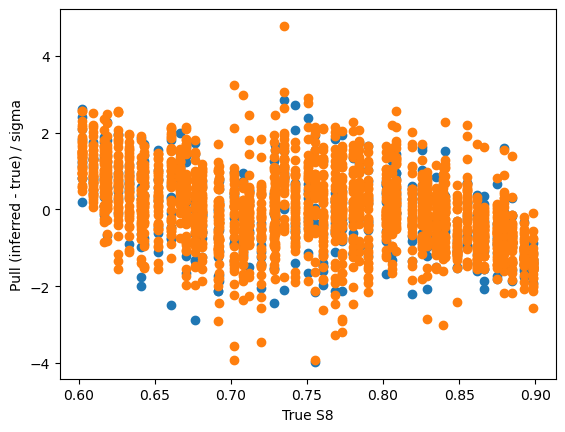

In [188]:
plt.scatter(theta_test[:,0], pull_test)
plt.scatter(theta_train[:,0], pull_trained)
plt.xlabel("True S8")
plt.ylabel("Pull (inferred - true) / sigma")

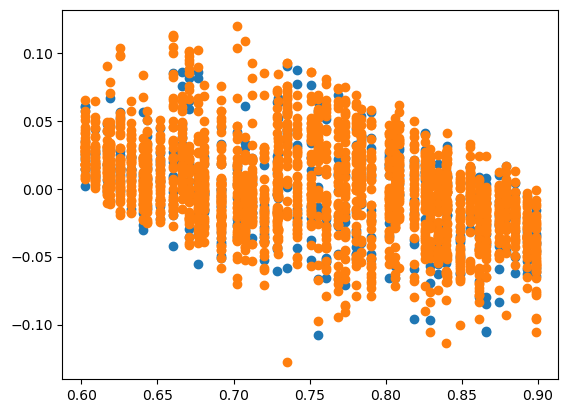

In [189]:
plt.scatter(theta_test[:,0], bias_test)
plt.scatter(theta_train[:,0], bias_trained)